# PINN Eigen-solver for the Finite Square Well with a Central Wall (PyTorch)

Same method as `finite_square_well_eigen.ipynb` (Jin, Mattheakis & Protopapas, arXiv:2203.00451), applied to a finite well split by a thin barrier at the center:

$$-\frac12\psi''(x)+V(x)\psi(x)=E\psi(x),\qquad V(x)=\begin{cases}V_0=20,&|x|\leq0.05\\0,&0.05<|x|\leq1.7\\V_0=20,&\text{otherwise}\end{cases},\quad\psi(\pm6)=0.$$

$V(x)$ is still even, so eigenfunctions are even or odd and the embedded-symmetry network applies unchanged. The wall mainly raises the even states (odd states already vanish at $x=0$).

### Method
- Network inputs $(x,E)$; $E$ is produced by a trainable `Linear(1, 1)` fed with ones.
- $\psi(x)=g(x)N(x,E)$, with $g(x)=(1-e^{-(x-x_L)})(1-e^{x-x_R})$.
- Embedded symmetry: $h(x)\pm h(-x)$ before the output layer gives exactly even/odd $\psi$.
- Loss $\mathcal L=\mathcal L_{DE}+\nu_{norm}\mathcal L_{norm}+\nu_{orth}\mathcal L_{orth}$.
- Solution recognition with patience and symmetry switching (Algorithm 1).

In [1]:
import copy
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from scipy.linalg import eigh_tridiagonal

torch.manual_seed(0)
np.random.seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
sns.set_theme(style="whitegrid", context="notebook")
print(f"Using device: {device}")

Using device: mps


In [2]:
# Problem
half_width = 1.7
wall_half_width = 0.05
V0 = 20.0
V_wall = 20.0
xL, xR = -6.0, 6.0

# Network / optimizer
M = 1200
hidden = 50
omega = 6.0  # input frequency scale for the sin network; resolves sharp features
lr = 8e-3
lr_decay_every, lr_min = 3000, 1e-4  # halve lr every N epochs within each state search

# Loss weights
nu_norm, nu_orth = 1.0, 1.0

# Solution recognition
n_states = 4
window = 1000
patience_tol = 1e-2  # relative improvement of mean L_DE between consecutive windows
de_tol = 5e-2  # applied to L_DE measured away from potential jumps
jump_band = 0.05  # half-width excluded around each jump of V when judging convergence
norm_tol = 5e-3
dup_E_tol = 0.05
min_epochs = 6000
max_epochs = 60000

In [3]:
class Sin(nn.Module):
    def forward(self, x):
        return torch.sin(x)


class EigenNet(nn.Module):
    """psi(x) = g(x) N(x, E) with trainable E and embedded even (+1) / odd (-1) parity."""

    def __init__(self, hidden=50, parity=1):
        super().__init__()
        self.parity = parity
        self.E_in = nn.Linear(1, 1)
        self.hidden = nn.Sequential(nn.Linear(2, hidden), Sin(), nn.Linear(hidden, hidden), Sin())
        self.out = nn.Linear(hidden, 1)

    def energy(self):
        return self.E_in(torch.ones(1, 1, device=self.E_in.weight.device)).squeeze()

    def forward(self, x):
        E = self.E_in(torch.ones_like(x))
        h = self.hidden(torch.cat([omega * x, E], 1))
        h_mirror = self.hidden(torch.cat([-omega * x, E], 1))
        N = self.out(h + self.parity * h_mirror)
        g = (1 - torch.exp(-(x - xL))) * (1 - torch.exp(x - xR))
        return g * N


def potential_np(x):
    ax = np.abs(x)
    return np.where(ax <= wall_half_width, V_wall, np.where(ax <= half_width, 0.0, V0))


def potential(x):
    ax = torch.abs(x)
    return torch.where(ax <= wall_half_width, V_wall * torch.ones_like(x),
                       torch.where(ax <= half_width, torch.zeros_like(x), V0 * torch.ones_like(x)))


grid = torch.linspace(xL, xR, M, device=device).reshape(-1, 1)
dx = (xR - xL) / (M - 1)


def sample_points():
    x = grid + 0.5 * dx * torch.randn_like(grid)
    return x.clamp(xL, xR).requires_grad_(True)


jumps = torch.tensor([-half_width, -wall_half_width, wall_half_width, half_width], device=device)


def away_from_jumps(x):
    return (torch.abs(x - jumps).min(dim=1, keepdim=True).values > jump_band).squeeze(1)


def compute_losses(model, x, stored):
    psi = model(x)
    E = model.energy()
    dpsi = torch.autograd.grad(psi, x, torch.ones_like(psi), create_graph=True)[0]
    d2psi = torch.autograd.grad(dpsi, x, torch.ones_like(dpsi), create_graph=True)[0]
    res2 = (-0.5 * d2psi + potential(x) * psi - E * psi) ** 2
    # divide by int psi^2 so the jump residual (~ psi^2) cannot be lowered by shrinking psi
    L_de = torch.mean(res2) / (torch.mean(psi**2) * (xR - xL))
    # jumps where V jumps, so a smooth network keeps a residual floor there; judge convergence elsewhere
    L_de_smooth = torch.mean(res2.detach()[away_from_jumps(x.detach())])
    # sqrt form keeps a non-zero gradient at the trivial solution psi = 0
    L_norm = (torch.sqrt(torch.mean(psi**2) * (xR - xL)) - 1.0) ** 2
    if stored:
        with torch.no_grad():
            psi_eigen = sum(m(x) for m in stored)
        # scale-invariant, so shrinking psi cannot reduce the overlap penalty
        L_orth = torch.mean(psi_eigen * psi) ** 2 / (torch.mean(psi_eigen**2) * torch.mean(psi**2))
    else:
        L_orth = torch.zeros((), device=x.device)
    return L_de, L_norm, L_orth, L_de_smooth

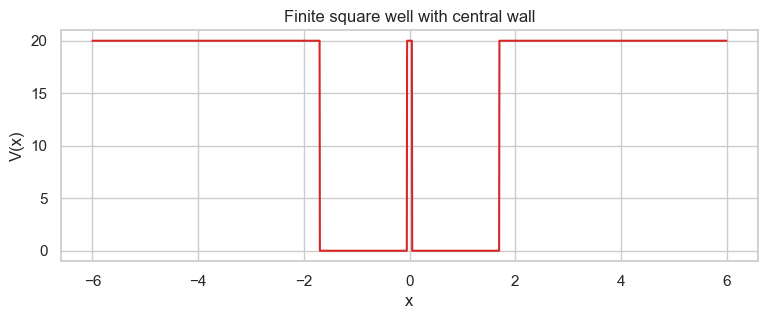

In [4]:
x_plot = np.linspace(xL, xR, 2000)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(x_plot, potential_np(x_plot), color="tab:red")
ax.set(xlabel="x", ylabel="V(x)", title="Finite square well with central wall")
plt.show()

## Training (Algorithm 1)

Start with an even network. After each accepted eigenstate, a frozen copy is added to $\phi_{eigen}$ and the network is re-initialized. A false solution triggers a symmetry switch. Even and odd states can be nearly degenerate with a central wall, so duplicates are only checked within the same parity.

**Why even states were missed before (and the fix):**
1. Where $V$ jumps, the exact $\psi''$ jumps by $2\Delta V\,\psi$. A smooth network cannot reproduce that, so $L_{DE}$ keeps a floor that grows with $\psi^2$ at each jump. Odd states have $\psi(0)=0$ and barely feel the wall, but even states are large at $x=\pm0.05$. Their $L_{DE}$ stalled near 5–6 × $10^{-2}$ with ~75% of it inside the wall, above `de_tol`, even though $E$ was already correct. Fix: patience and acceptance use `L_DE_smooth` on points farther than `jump_band` from any jump of $V$ (training still uses all points).
2. After a rejected even state the search switched to odd, and nothing capped the number of odd states, so the 4 slots filled with odd states. Fix: for a symmetric 1D well the lowest states alternate even/odd, so each parity has a quota of `n_states / 2`; a parity whose quota is full is never searched again.
3. The jump residual scales with $\int\psi^2$, so the optimizer shrank high even states (large $\psi$ at the wall) below unit norm and `L_norm` failed `norm_tol` although $E$ was correct. Fix: training `L_DE` is divided by $\int\psi^2$, making it scale-invariant so only `L_norm` sets the amplitude.
4. With a re-initialized network, `L_DE` pulls strongly toward the nearest already-found state, and the soft `L_orth` (whose gradient vanishes at full overlap) could not prevent re-converging to duplicates. Fix: orthogonality is enforced exactly by projecting the already-found same-parity states out of the network output (`Orthogonalized`, Gram–Schmidt with coefficients from the fixed grid); `L_orth` is kept as in the paper but is now ~0.

In [5]:
class Orthogonalized(nn.Module):
    """Network output with already-found same-parity eigenstates projected out (Gram-Schmidt on grid)."""

    def __init__(self, net, basis):
        super().__init__()
        self.net = net
        self.basis = nn.ModuleList(basis)
        self.parity = net.parity

    def energy(self):
        return self.net.energy()

    def forward(self, x):
        psi = self.net(x)
        psi_g = self.net(grid)
        # coefficients come from the fixed grid, so they are constants w.r.t. x and psi'' stays exact
        for phi in self.basis:
            phi_g = phi(grid)
            c = (phi_g * psi_g).sum() / (phi_g**2).sum()
            psi = psi - c * phi(x)
            psi_g = psi_g - c * phi_g
        return psi


def new_model(parity):
    basis = [m for m in stored_models if m.parity == parity]
    m = Orthogonalized(EigenNet(hidden, parity), basis).to(device)
    return m, torch.optim.Adam(m.net.parameters(), lr=lr)


def set_lr(opt, epochs_in_state):
    for group in opt.param_groups:
        group['lr'] = max(lr * 0.5 ** (epochs_in_state // lr_decay_every), lr_min)


# Even/odd states alternate in a symmetric 1D well, so the lowest n_states split evenly by parity
quota = {+1: (n_states + 1) // 2, -1: n_states // 2}


def next_parity(current):
    remaining = [p for p in (-current, current) if sum(q == p for _, q in found) < quota[p]]
    return remaining[0]


stored_models, found, events, history = [], [], [], []
model, optimizer = new_model(parity=+1)
last_event = 0
t_start = time.time()

for epoch in range(max_epochs):
    x = sample_points()
    L_de, L_norm, L_orth, L_de_smooth = compute_losses(model, x, stored_models)
    loss = L_de + nu_norm * L_norm + nu_orth * L_orth
    set_lr(optimizer, epoch - last_event)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    E = model.energy().item()
    history.append({'epoch': epoch, 'E': E, 'L_DE': L_de.item(), 'L_DE_smooth': L_de_smooth.item(),
                    'L_norm': L_norm.item(), 'L_orth': L_orth.item(), 'parity': model.parity})

    if epoch % 1000 == 0:
        print(f"Epoch {epoch:6d} | parity {model.parity:+d} | E {E:.4f} | L_DE {L_de.item():.2e} "
              f"| L_DE_smooth {L_de_smooth.item():.2e} | L_norm {L_norm.item():.2e} "
              f"| L_orth {L_orth.item():.2e} | {time.time() - t_start:.0f}s")

    if epoch - last_event < max(min_epochs, 2 * window):
        continue
    de_recent = [h['L_DE_smooth'] for h in history[-2 * window:]]
    prev, cur = np.mean(de_recent[:window]), np.mean(de_recent[window:])
    if (prev - cur) / prev >= patience_tol:
        continue

    is_duplicate = any(abs(E - E_found) < dup_E_tol and p == model.parity for E_found, p in found)
    if cur < de_tol and L_norm.item() < norm_tol and not is_duplicate:
        frozen = copy.deepcopy(model).eval().requires_grad_(False)
        stored_models.append(frozen)
        found.append((E, model.parity))
        events.append({'epoch': epoch, 'event': 'stored', 'E': E})
        print(f"  >> stored eigenstate E = {E:.4f} (parity {model.parity:+d}) at epoch {epoch}")
        if len(found) == n_states:
            break
        model, optimizer = new_model(next_parity(model.parity))
    else:
        events.append({'epoch': epoch, 'event': 'switch', 'E': E})
        print(f"  >> false solution E = {E:.4f} | L_DE_smooth {cur:.2e}, L_norm {L_norm.item():.1e}; switching parity")
        model, optimizer = new_model(next_parity(model.parity))
    last_event = epoch

print(f"Found {len(found)} states in {time.time() - t_start:.0f}s: {[round(e, 4) for e, _ in found]}")

Epoch      0 | parity +1 | E 0.5450 | L_DE 4.46e+01 | L_DE_smooth 1.28e+01 | L_norm 2.21e-01 | L_orth 0.00e+00 | 3s
Epoch   1000 | parity +1 | E 0.9205 | L_DE 7.75e-02 | L_DE_smooth 1.02e-02 | L_norm 1.12e-05 | L_orth 0.00e+00 | 10s
Epoch   2000 | parity +1 | E 0.9468 | L_DE 6.72e-02 | L_DE_smooth 7.87e-03 | L_norm 2.35e-05 | L_orth 0.00e+00 | 16s
Epoch   3000 | parity +1 | E 0.9352 | L_DE 6.04e-02 | L_DE_smooth 1.37e-02 | L_norm 3.83e-06 | L_orth 0.00e+00 | 22s
Epoch   4000 | parity +1 | E 0.9614 | L_DE 8.04e-02 | L_DE_smooth 8.66e-03 | L_norm 2.27e-05 | L_orth 0.00e+00 | 28s
Epoch   5000 | parity +1 | E 0.9614 | L_DE 5.66e-02 | L_DE_smooth 6.63e-03 | L_norm 4.51e-05 | L_orth 0.00e+00 | 33s
Epoch   6000 | parity +1 | E 0.9635 | L_DE 5.42e-02 | L_DE_smooth 6.00e-03 | L_norm 3.70e-05 | L_orth 0.00e+00 | 39s
  >> stored eigenstate E = 0.9635 (parity +1) at epoch 6000
Epoch   7000 | parity -1 | E 1.4354 | L_DE 3.80e-02 | L_DE_smooth 1.03e-02 | L_norm 7.74e-07 | L_orth 2.20e-06 | 46s
Epoch

## Reference solution

Finite-difference Hamiltonian on the same truncated domain with Dirichlet boundaries, diagonalized with `eigh_tridiagonal`. The grid spacing (0.003) puts ~33 points inside the wall.

In [6]:
n_fd = 4000
x_fd = np.linspace(xL, xR, n_fd + 2)[1:-1]
h_fd = x_fd[1] - x_fd[0]
E_ref, psi_fd = eigh_tridiagonal(1.0 / h_fd**2 + potential_np(x_fd),
                                -0.5 / h_fd**2 * np.ones(n_fd - 1),
                                select='i', select_range=(0, n_states - 1))
x_np = np.linspace(xL, xR, 1000)
psi_ref = np.stack([np.interp(x_np, x_fd, psi_fd[:, k], 0.0, 0.0) for k in range(n_states)])
psi_ref /= np.sqrt(np.trapezoid(psi_ref**2, x_np, axis=1))[:, None]
print("Reference energies:", np.round(E_ref, 4))

Reference energies: [0.9599 1.428  4.1315 5.6712]


In [7]:
order = np.argsort([E for E, _ in found])
x_t = torch.tensor(x_np, dtype=torch.float32, device=device).reshape(-1, 1)

rows, psi_pinn = [], []
for idx in order:
    E_p, parity = found[idx]
    k = int(np.argmin(np.abs(E_ref - E_p)))
    with torch.no_grad():
        psi = stored_models[idx](x_t).cpu().numpy().ravel()
    psi /= np.sqrt(np.trapezoid(psi**2, x_np))
    # Global sign of an eigenfunction is arbitrary
    if np.dot(psi, psi_ref[k]) < 0:
        psi = -psi
    psi_pinn.append(psi)
    rows.append({'state': k, 'parity': 'even' if parity > 0 else 'odd', 'E_PINN': E_p, 'E_ref': E_ref[k],
                 'E rel. err (%)': 100 * abs(E_p - E_ref[k]) / E_ref[k],
                 'MSE / max|psi_ref|': np.mean((psi - psi_ref[k]) ** 2) / np.max(np.abs(psi_ref[k]))})
psi_pinn = np.array(psi_pinn)
df_results = pd.DataFrame(rows)
df_results

,state,parity,E_PINN,E_ref,E rel. err (%),MSE / max|psi_ref|
0,0,even,0.963501,0.959855,0.379880,0.000419
1,1,odd,1.428810,1.428021,0.055247,0.000017
2,2,even,4.116632,4.131459,0.358894,0.000622
3,3,odd,5.675725,5.671176,0.080229,0.000037


In [8]:
overlap = np.array([[np.trapezoid(pi * pj, x_np) for pj in psi_pinn] for pi in psi_pinn])
pd.DataFrame(overlap, index=df_results['state'], columns=df_results['state']).round(4)

state,0,1,2,3
state,,,,
0,1.0000,0.0002,-0.0,0.0005
1,0.0002,1.0000,0.0,-0.0000
2,-0.0000,0.0000,1.0,0.0000
3,0.0005,-0.0000,0.0,1.0000


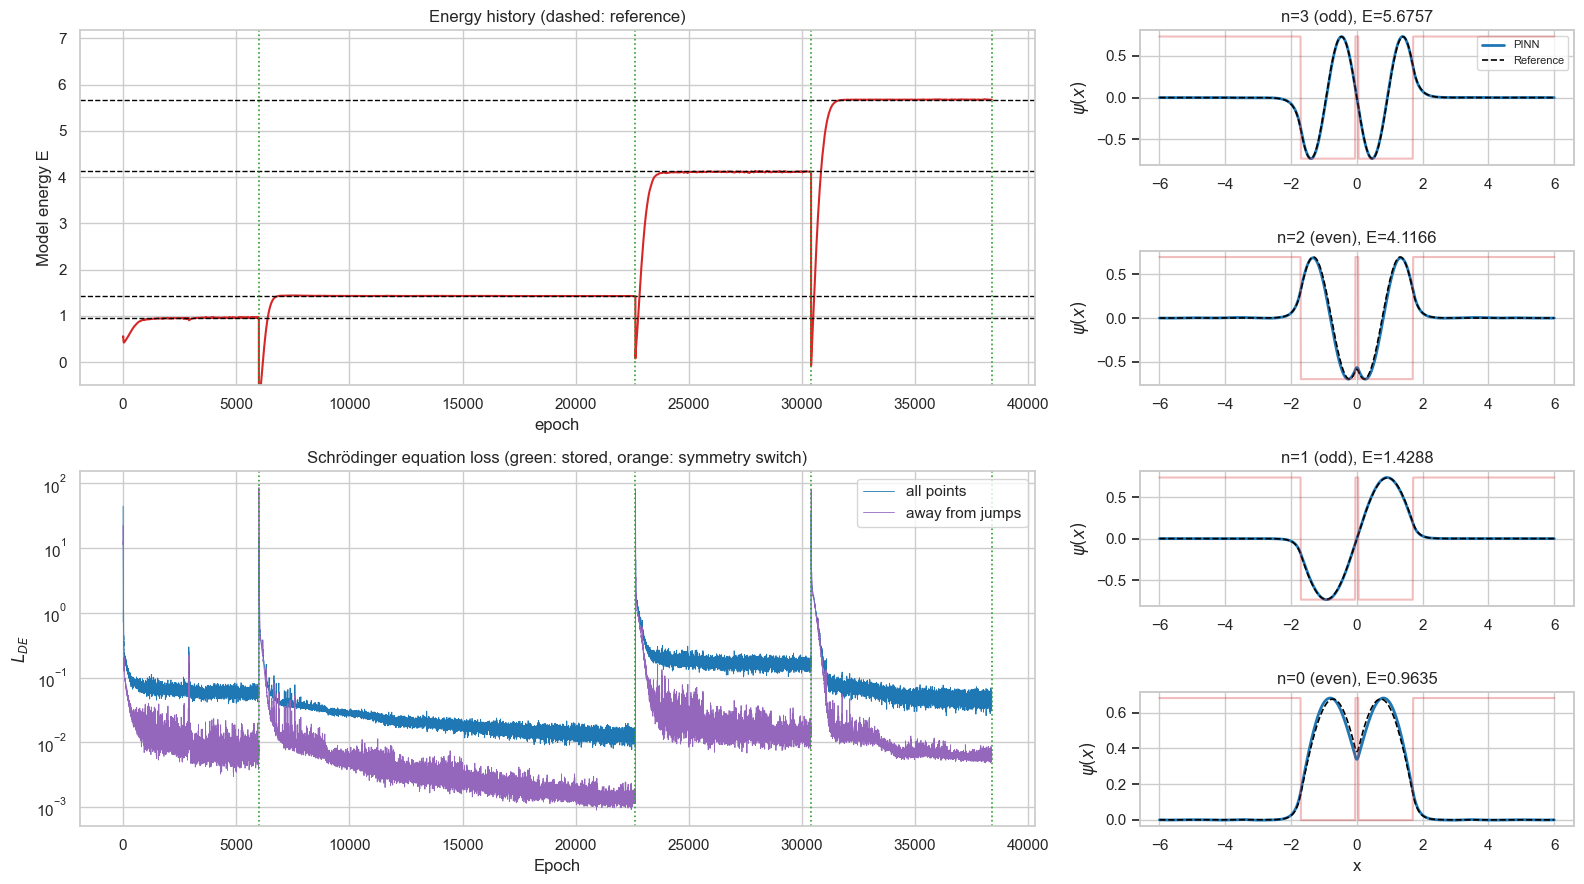

In [9]:
df_hist = pd.DataFrame(history)
df_events = pd.DataFrame(events)

fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(len(psi_pinn), 2, width_ratios=[2.2, 1])
ax_E = fig.add_subplot(gs[:len(psi_pinn) // 2, 0])
ax_L = fig.add_subplot(gs[len(psi_pinn) // 2:, 0], sharex=ax_E)

sns.lineplot(data=df_hist, x='epoch', y='E', color='tab:red', ax=ax_E)
for E_k in E_ref:
    ax_E.axhline(E_k, color='black', linestyle='--', linewidth=1)
ax_E.set(ylim=(-0.5, E_ref.max() + 1.5), ylabel='Model energy E', title='Energy history (dashed: reference)')

sns.lineplot(data=df_hist, x='epoch', y='L_DE', color='tab:blue', linewidth=0.6, ax=ax_L, label='all points')
sns.lineplot(data=df_hist, x='epoch', y='L_DE_smooth', color='tab:purple', linewidth=0.6, ax=ax_L,
             label='away from jumps')
for _, ev in df_events.iterrows():
    color = 'tab:green' if ev['event'] == 'stored' else 'tab:orange'
    for a in (ax_E, ax_L):
        a.axvline(ev['epoch'], color=color, linestyle=':', linewidth=1.2)
ax_L.set(yscale='log', xlabel='Epoch', ylabel=r'$L_{DE}$',
         title='Schrödinger equation loss (green: stored, orange: symmetry switch)')

V_np = potential_np(x_np)
for i, row in df_results.iloc[::-1].reset_index(drop=True).iterrows():
    j = len(psi_pinn) - 1 - i
    ax = fig.add_subplot(gs[i, 1])
    ax.plot(x_np, psi_pinn[j], color='tab:blue', linewidth=2, label='PINN')
    ax.plot(x_np, psi_ref[int(row['state'])], color='black', linestyle='--', linewidth=1.2, label='Reference')
    ax_v = ax.twinx()
    ax_v.plot(x_np, V_np, color='tab:red', alpha=0.3)
    ax_v.set(yticks=[])
    ax_v.grid(False)
    ax.set(ylabel=r'$\psi(x)$', title=f"n={row['state']} ({row['parity']}), E={row['E_PINN']:.4f}")
    if i == 0:
        ax.legend(loc='upper right', fontsize=8)
    if i == len(psi_pinn) - 1:
        ax.set(xlabel='x')
plt.tight_layout()
plt.show()

In [11]:
fig.savefig("finite_square_well_central_wall_PINN_results.png", bbox_inches="tight")